# Лабораторная работа № 1. Обучение с учителем


[Датасет Iranian Churn — UCI](https://archive.ics.uci.edu/dataset/563/iranian%2Bchurn%2Bdataset)

| Признак | Тип | Описание |
|---|---|---|
| `Call Failure` | Количественный | Количество неудачных вызовов |
| `Complains` | Категориальный | 0 — нет жалобы; 1 — есть жалоба |
| `Subscription Length` | Количественный | Продолжительность подписки, месяцы |
| `Charge Amount` | Порядковый | Уровни 0–9: от минимального к максимальному |
| `Seconds of Use` | Количественный | Суммарная длительность звонков, секунды |
| `Frequency of use` | Количественный | Общее количество звонков |
| `Frequency of SMS` | Количественный | Общее количество текстовых сообщений |
| `Distinct Called Numbers` | Количественный | Число различных вызываемых номеров |
| `Age Group` | Порядковый | Группы 1–5: от младшей к старшей |
| `Tariff Plan` | Категориальный | 1 — оплата по факту; 2 — контракт |
| `Status` | Категориальный | 1 — активный; 2 — неактивный |
| `Age` | Количественный | Возрастное поле; в выборке принимает пять значений |
| `Customer Value` | Количественный | Расчётная ценность клиента; формула не указана |
| `Churn` | Таргет | 0 — остался; 1 — ушёл |

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

project_root = next(
    p for p in [Path.cwd(), *Path.cwd().parents]
    if (p / "data/raw/Customer Churn.csv").is_file()
)
df = pd.read_csv(project_root / "data/raw/Customer Churn.csv")
df.columns = [" ".join(column.split()) for column in df.columns]
TARGET = "Churn"

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 11,
    "axes.titlesize": 12,
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

labels = {'Call Failure': 'Неудачные вызовы', 'Complains': 'Жалобы', 'Subscription Length': 'Длительность подписки', 'Charge Amount': 'Уровень оплаты', 'Seconds of Use': 'Длительность разговоров', 'Frequency of use': 'Количество звонков', 'Frequency of SMS': 'Количество SMS', 'Distinct Called Numbers': 'Различные номера', 'Age Group': 'Возрастная группа', 'Tariff Plan': 'Тарифный план', 'Status': 'Статус клиента', 'Age': 'Возраст (Age)', 'Customer Value': 'Ценность клиента', 'Churn': 'Отток'}

from sklearn.metrics import (
    accuracy_score,
    fbeta_score,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)

def classification_metrics(target, probability):
    prediction = (np.asarray(probability) > 0.5).astype(int)
    return {
        "Accuracy": accuracy_score(target, prediction),
        "Precision": precision_score(target, prediction, zero_division=0),
        "Recall": recall_score(target, prediction, zero_division=0),
        "F1": f1_score(target, prediction, zero_division=0),
        "F2": fbeta_score(target, prediction, beta=2, zero_division=0),
        "ROC-AUC": roc_auc_score(target, probability),
    }

results_dir = project_root / "results"
results_dir.mkdir(parents=True, exist_ok=True)

## Анализ датасета

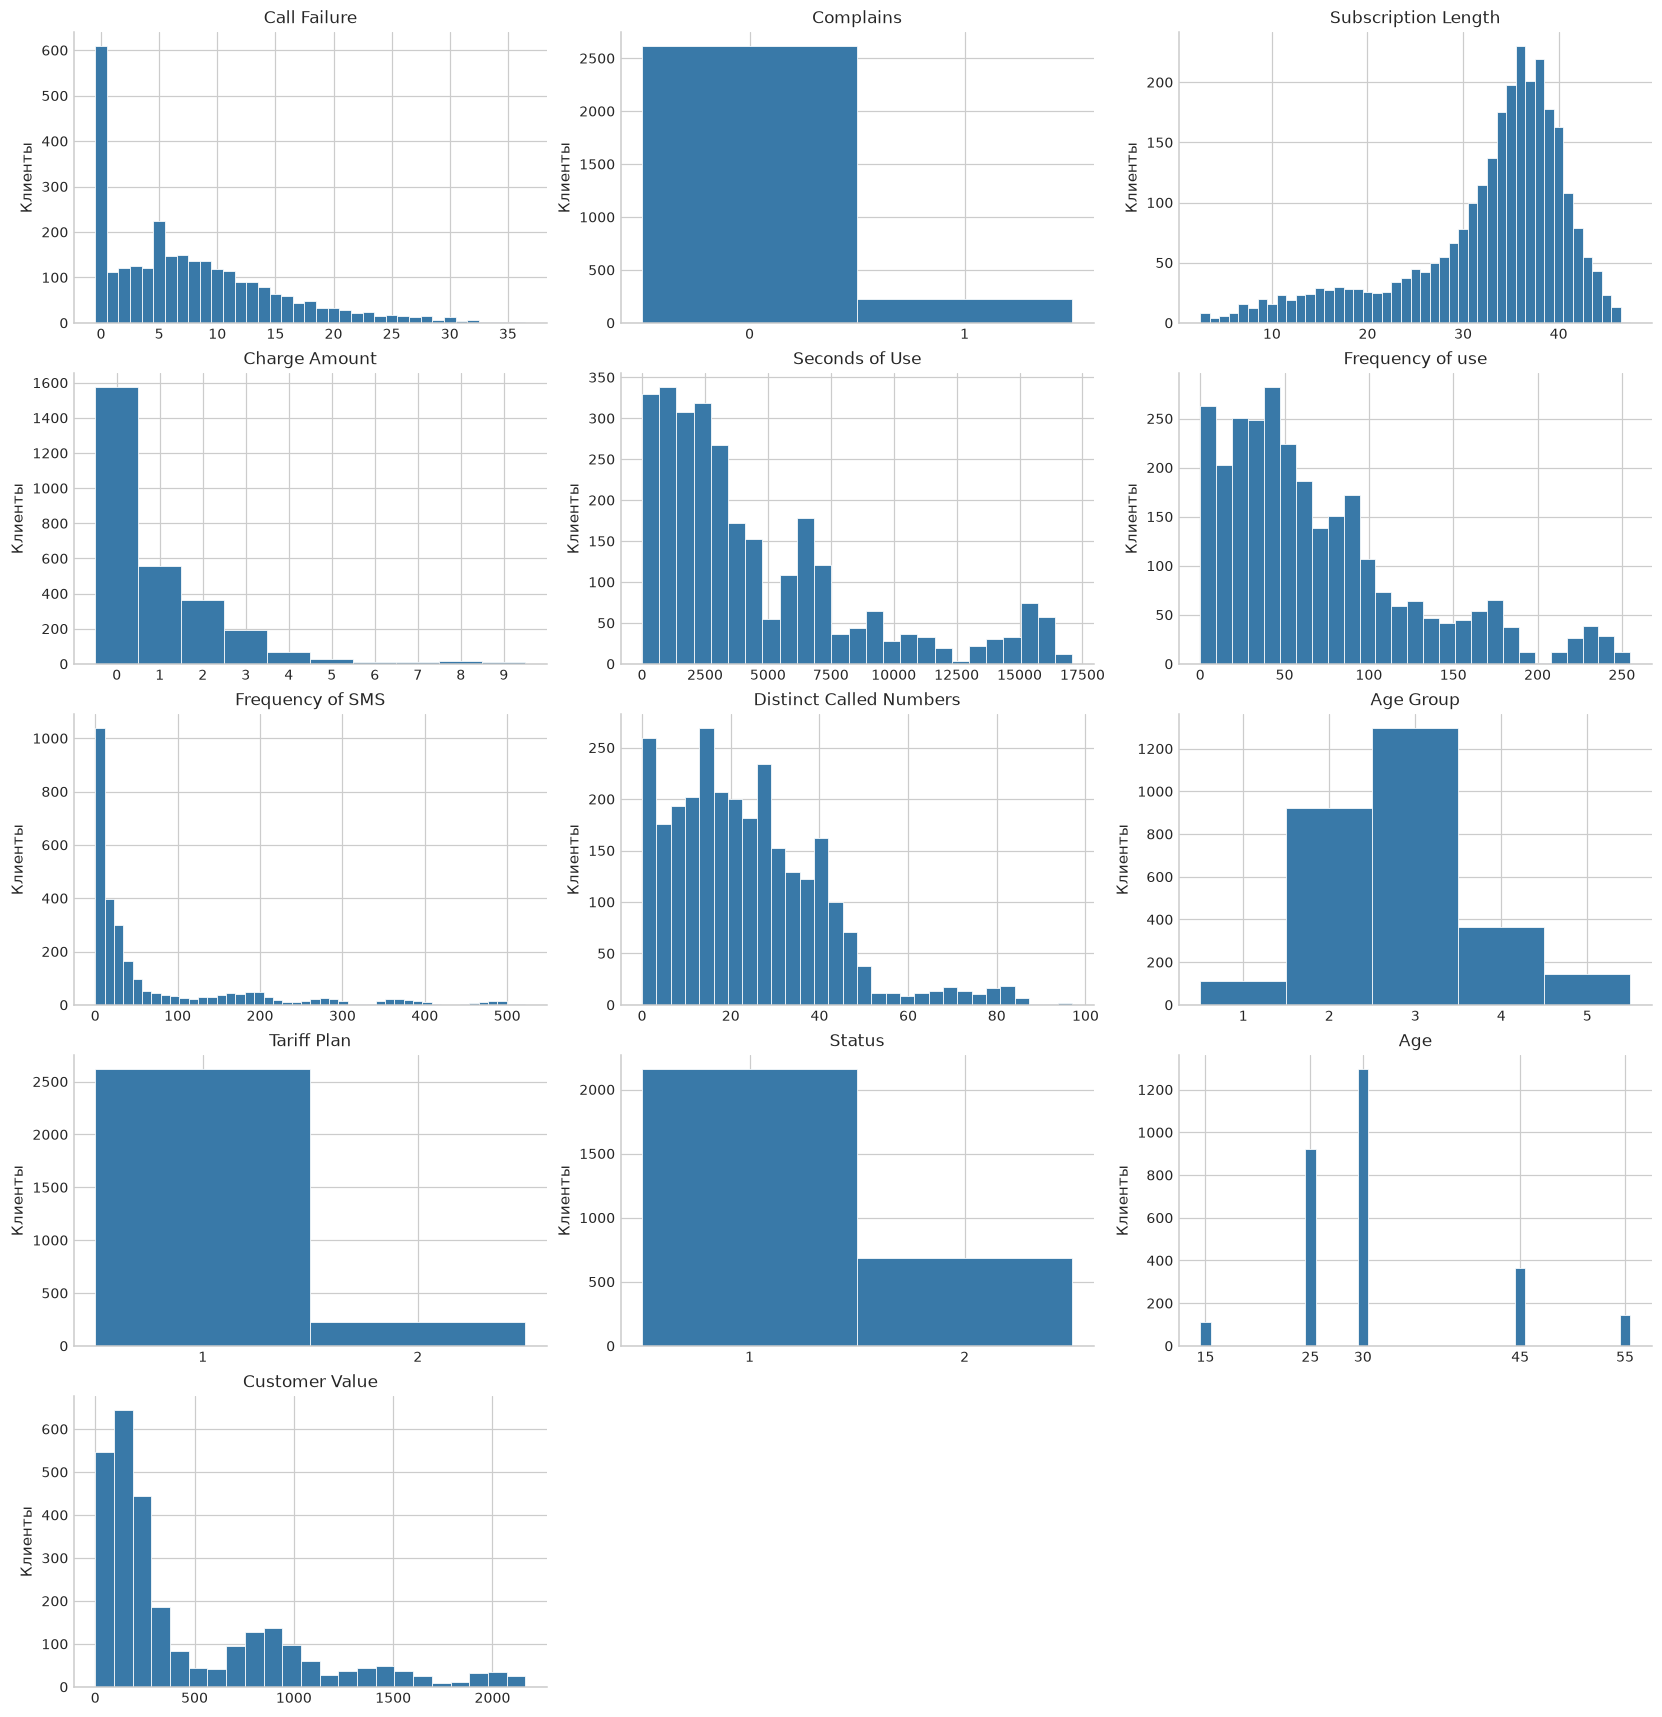

In [2]:
histogram_features = df.drop(columns=TARGET).columns.tolist()
discrete_values = {
    "Complains": [0, 1], "Charge Amount": list(range(10)),
    "Age Group": list(range(1, 6)), "Tariff Plan": [1, 2],
    "Status": [1, 2], "Age": sorted(df["Age"].unique().tolist()),
}
fig, axes = plt.subplots(5, 3, figsize=(15, 15.5), layout="constrained")
for ax, column in zip(axes.flat, histogram_features):
    values = df[column].to_numpy()
    if column in discrete_values:
        ticks = discrete_values[column]
        bins = np.arange(min(ticks) - 0.5, max(ticks) + 1.5, 1)
        ax.set_xticks(ticks)
    elif pd.api.types.is_integer_dtype(df[column]) and values.max() - values.min() <= 60:
        bins = np.arange(values.min() - 0.5, values.max() + 1.5, 1)
    else:
        bins = np.histogram_bin_edges(values, bins="fd")
    ax.hist(values, bins=bins, color="#3979A8", edgecolor="white", linewidth=0.5)
    ax.set_title(column, fontsize=11)
    ax.set_ylabel("Клиенты", fontsize=10)
    ax.tick_params(labelsize=9)
for ax in axes.flat[len(histogram_features):]:
    ax.set_visible(False)
plt.show()

Активность звонков, SMS и ценность клиента имеют длинный правый хвост.
`Age` принимает пять значений и полностью определяется через `Age Group`.

### Отток по категориям

Попробуем выявить основные предикторы. Посмотрим процент ушедших по категориям `Complains`, `Tariff plan` и `Status`.

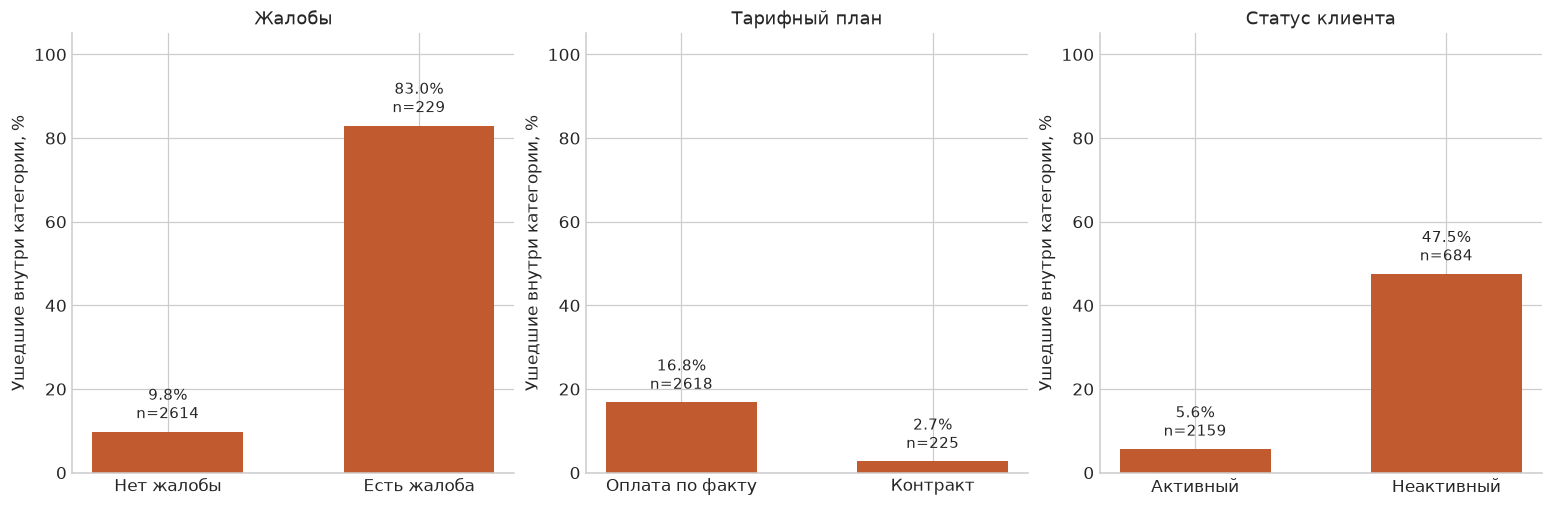

In [3]:
category_names = {
    "Complains": ["Нет жалобы", "Есть жалоба"],
    "Tariff Plan": ["Оплата по факту", "Контракт"],
    "Status": ["Активный", "Неактивный"],
}
category_churn_stats = {}
fig, axes = plt.subplots(1, 3, figsize=(14, 4.5), layout="constrained")
for ax, column in zip(axes, category_names):
    stats = df.groupby(column)[TARGET].agg(["count", "sum", "mean"])
    stats["Ушли, %"] = stats["mean"] * 100
    category_churn_stats[column] = stats
    positions = np.arange(len(stats))
    ax.bar(positions, stats["Ушли, %"], color="#C25A30", width=0.6)
    for position, rate, count in zip(positions, stats["Ушли, %"], stats["count"]):
        ax.text(position, rate + 2, f"{rate:.1f}%" + chr(10) + f"n={count}",
                ha="center", va="bottom", fontsize=10)
    ax.set_xticks(positions, category_names[column])
    ax.set_title(labels[column])
    ax.set_ylabel("Ушедшие внутри категории, %")
    ax.set_ylim(0, 105)
plt.show()

В качестве важного предиктора может выступать наличие жалобы - 83% клиентов с жалобой ушло. Используем это наблюдение в Baseline решении.

### Распределение целевой переменной

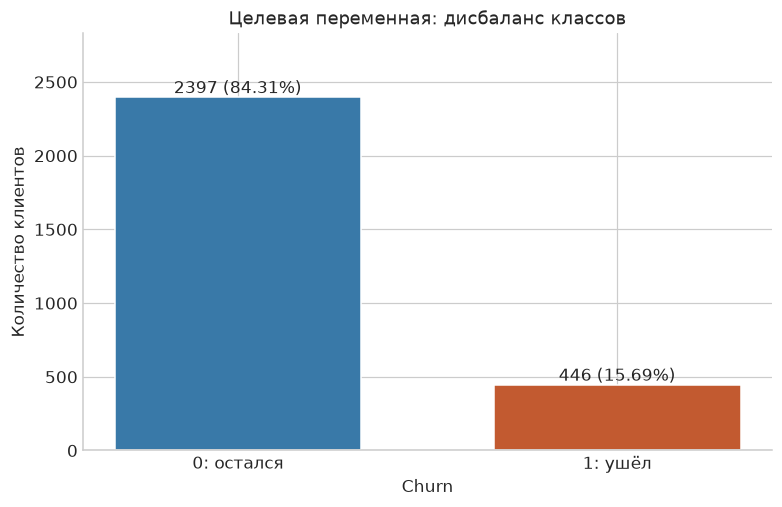

In [4]:
from IPython.display import Markdown, display
fig, ax = plt.subplots(figsize=(7, 4.5), layout="constrained")
counts, edges, patches = ax.hist(
    df[TARGET], bins=[-0.5, 0.5, 1.5], rwidth=0.65, edgecolor="white"
)
for patch, color in zip(patches, ["#3979A8", "#C25A30"]):
    patch.set_facecolor(color)
for count, x in zip(counts, [0, 1]):
    ax.text(x, count, f"{int(count)} ({count / len(df):.2%})", ha="center", va="bottom")
ax.set_xticks([0, 1], ["0: остался", "1: ушёл"])
ax.set_ylim(0, max(counts) * 1.18)
ax.set_xlabel("Churn")
ax.set_ylabel("Количество клиентов")
ax.set_title("Целевая переменная: дисбаланс классов")
plt.show()

Ушли **446 клиентов (15,69%)**. Видим дисбаланс классов, учтем его позже при анализе метрик.

## Разделение данных

Используем **60% train / 20% validation / 20% test** с сохранением доли классов. Train используется для обучения, validation — для подбора параметров, test — для итоговой оценки.

In [5]:
from sklearn.model_selection import StratifiedGroupKFold

X_source = df.drop(columns=TARGET)
y = df[TARGET].copy()
profile_ids = X_source.groupby(list(X_source.columns), sort=False, dropna=False).ngroup()
splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
fold_id = np.empty(len(df), dtype=int)
for fold, (_, indices) in enumerate(splitter.split(X_source, y, groups=profile_ids)):
    fold_id[indices] = fold
split_indices = {
    "train": df.index[fold_id >= 2],
    "val": df.index[fold_id == 1],
    "test": df.index[fold_id == 0],
}
X_train_raw, y_train = X_source.loc[split_indices["train"]].copy(), y.loc[split_indices["train"]].copy()
X_val_raw, y_val = X_source.loc[split_indices["val"]].copy(), y.loc[split_indices["val"]].copy()
X_test_raw, y_test = X_source.loc[split_indices["test"]].copy(), y.loc[split_indices["test"]].copy()
raw_splits = {
    "train": (X_train_raw, y_train), "val": (X_val_raw, y_val), "test": (X_test_raw, y_test),
}
split_summary = pd.DataFrame([
    {"Выборка": name, "Клиентов": len(target), "Ушли": int(target.sum()),
     "Доля оттока, %": round(target.mean() * 100, 2)}
    for name, (_, target) in raw_splits.items()
]).set_index("Выборка")
split_summary

,Клиентов,Ушли,"Доля оттока, %"
Выборка,,,
train,1705,267,15.66
val,569,90,15.82
test,569,89,15.64


## Baseline по наличию жалобы

Если у клиента есть жалоба (`Complains = 1`), прогнозируем отток **1**, иначе — **0**.
По анализу данных, среди клиентов с жалобой ушли около 83%, без жалобы — около 9,8%.
Правило не требует обучения, но пропускает всех ушедших клиентов без жалоб.

In [6]:
baseline_predictions, baseline_scores, baseline_rows = {}, {}, []
for name, (features, target) in raw_splits.items():
    prediction = features["Complains"].eq(1).astype(int).to_numpy()
    score = prediction.astype(float)
    baseline_predictions[name] = prediction
    baseline_scores[name] = score
    baseline_rows.append({"Выборка": name, **classification_metrics(target, score)})
baseline_metrics = pd.DataFrame(baseline_rows).set_index("Выборка")
baseline_metrics.to_csv(results_dir / "baseline_metrics.csv")

## Случайный лес и подготовка признаков

В качестве основной модели будем использовать случайный лес для классификации.

Для подготовки достаточно кодирования категорий: бинарные поля приводим к 0/1,
`Charge Amount` и `Age Group` — к one-hot encoding. `Age` удаляем как дублирующий признак.
Количественные значения сохраняем: масштабирование для леса не требуется.

In [7]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

binary_mappings = {"Complains": {0: 0, 1: 1}, "Tariff Plan": {1: 0, 2: 1}, "Status": {1: 0, 2: 1}}
def prepare_binary(features):
    prepared = features.drop(columns="Age").copy()
    for column, mapping in binary_mappings.items():
        prepared[column] = prepared[column].map(mapping).astype("int64")
    return prepared

preprocessor = ColumnTransformer(
    [("categorical", OneHotEncoder(
        categories=[list(range(10)), list(range(1, 6))],
        handle_unknown="ignore", sparse_output=False, dtype=np.int64,
    ), ["Charge Amount", "Age Group"])],
    remainder="passthrough", verbose_feature_names_out=False,
).set_output(transform="pandas")
X_train = preprocessor.fit_transform(prepare_binary(X_train_raw))
X_val = preprocessor.transform(prepare_binary(X_val_raw))
X_test = preprocessor.transform(prepare_binary(X_test_raw))
splits = {"train": (X_train, y_train), "val": (X_val, y_val), "test": (X_test, y_test)}
processed_dir = project_root / "data/processed"
processed_dir.mkdir(parents=True, exist_ok=True)
for name, (features, target) in splits.items():
    features.assign(Churn=target).to_csv(processed_dir / f"{name}.csv", index=False)

## Случайный лес sklearn

Для обеих реализаций проверяем одинаковые **30 из 64 комбинаций** трёх гиперпараметров: `n_estimators ∈ {50, 100, 200, 400}`, `max_depth ∈ {4, 8, 12, None}`, `min_samples_leaf ∈ {1, 2, 5, 10}`.

Выбираем конфигурацию с максимальной **F2 на validation**.

Положительный класс — ушедшие клиенты; их около 16%. Для задачи удержания важнее
обнаружить ушедшего клиента, чем избежать ложного предупреждения. Поэтому используем
**F2** (β = 2), которая придаёт recall больший вес, чем precision, но учитывает обе метрики:

$$F_2 = \frac{5 \cdot Precision \cdot Recall}{4 \cdot Precision + Recall}
= \frac{5TP}{5TP + 4FN + FP}.$$

В этой формуле пропуск ушедшего клиента (FN) имеет в четыре раза больший вес,
чем ложное предупреждение (FP).

In [8]:
from time import perf_counter
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import ParameterSampler


rf_fixed_params = {
    "criterion": "gini",
    "bootstrap": True,
    "max_features": "sqrt",
    "min_samples_split": 2,
    "class_weight": None,
    "random_state": 42,
    "n_jobs": -1,
}
initial_params = {"n_estimators": 100, "max_depth": None, "min_samples_leaf": 1}
started = perf_counter()
initial_rf = RandomForestClassifier(**rf_fixed_params, **initial_params).fit(X_train, y_train)
initial_fit_seconds = perf_counter() - started
initial_train_metrics = classification_metrics(y_train, initial_rf.predict_proba(X_train)[:, 1])
initial_val_metrics = classification_metrics(y_val, initial_rf.predict_proba(X_val)[:, 1])

parameter_space = {
    "n_estimators": [50, 100, 200, 400],
    "max_depth": [4, 8, 12, None],
    "min_samples_leaf": [1, 2, 5, 10],
}
parameter_sets = list(ParameterSampler(parameter_space, n_iter=30, random_state=42))
search_rows = []
best_rf, best_params, best_val_f2 = None, None, -np.inf
for trial, params in enumerate(parameter_sets, start=1):
    if params == initial_params:
        model = initial_rf
        fit_seconds = initial_fit_seconds
    else:
        started = perf_counter()
        model = RandomForestClassifier(**rf_fixed_params, **params).fit(X_train, y_train)
        fit_seconds = perf_counter() - started
    train_metrics = classification_metrics(y_train, model.predict_proba(X_train)[:, 1])
    val_metrics = classification_metrics(y_val, model.predict_proba(X_val)[:, 1])
    search_rows.append({
        "Конфигурация": trial,
        "n_estimators": params["n_estimators"],
        "max_depth": "None" if params["max_depth"] is None else str(params["max_depth"]),
        "min_samples_leaf": params["min_samples_leaf"],
        "F2 train": train_metrics["F2"],
        "F2 validation": val_metrics["F2"],
        "Разрыв F2": train_metrics["F2"] - val_metrics["F2"],
        "F1 train": train_metrics["F1"],
        "F1 validation": val_metrics["F1"],
        "Время обучения, с": fit_seconds,
    })
    if val_metrics["F2"] > best_val_f2:
        best_rf = model
        best_params = dict(params)
        best_val_f2 = val_metrics["F2"]

rf_search_results = pd.DataFrame(search_rows).sort_values(
    "F2 validation", ascending=False, kind="stable"
).reset_index(drop=True)
results_dir = project_root / "results"
results_dir.mkdir(parents=True, exist_ok=True)
rf_search_results.to_csv(results_dir / "sklearn_rf_search.csv", index=False)

После выбора гиперпараметров покажем recall на train и validation после каждого
добавленного дерева. Деревья леса обучаются независимо на bootstrap-выборках;
точка графика — качество усреднённого прогноза первых k деревьев.

Выбрано: **100 деревьев**, `max_depth=None`, `min_samples_leaf=1`; F2 validation — **0.8124**.

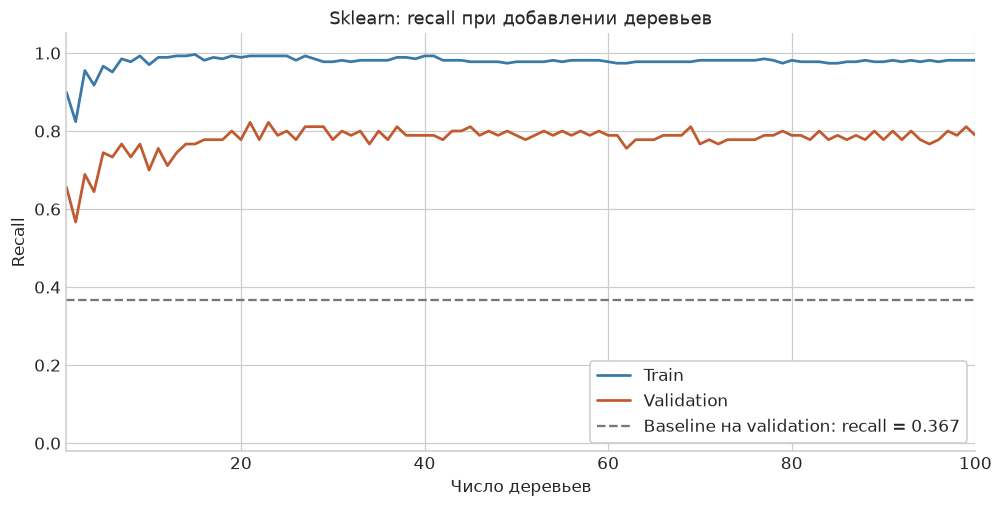

In [9]:
growing_rf = RandomForestClassifier(
    **{**rf_fixed_params, "n_jobs": 1},
    **{**best_params, "n_estimators": 1},
    warm_start=True,
)
curve_features = {
    "train": X_train.to_numpy(dtype=np.float32),
    "val": X_val.to_numpy(dtype=np.float32),
}
curve_targets = {"train": y_train, "val": y_val}
probability_sums = {name: np.zeros(len(target)) for name, target in curve_targets.items()}
curve_rows = []
for tree_count in range(1, best_params["n_estimators"] + 1):
    growing_rf.set_params(n_estimators=tree_count)
    growing_rf.fit(X_train, y_train)
    newest_tree = growing_rf.estimators_[-1]
    for name, features in curve_features.items():
        probability_sums[name] += newest_tree.predict_proba(features)[:, 1]
        probability = probability_sums[name] / tree_count
        curve_rows.append({
            "Деревьев": tree_count,
            "Выборка": name,
            **classification_metrics(curve_targets[name], probability),
        })

rf_learning_curve = pd.DataFrame(curve_rows)
rf_learning_curve.to_csv(results_dir / "sklearn_rf_learning_curve.csv", index=False)

rf_probabilities = {}
rf_predictions = {}
rf_rows = []
for name, (features, target) in splits.items():
    probability = best_rf.predict_proba(features)[:, 1]
    rf_probabilities[name] = probability
    rf_predictions[name] = (probability > 0.5).astype(int)
    rf_rows.append({"Выборка": name, **classification_metrics(target, probability)})

rf_metrics = pd.DataFrame(rf_rows).set_index("Выборка")
rf_metrics.to_csv(results_dir / "sklearn_rf_metrics.csv")

display(Markdown(
    f"Выбрано: **{best_params['n_estimators']} деревьев**, "
    f"`max_depth={best_params['max_depth']}`, `min_samples_leaf={best_params['min_samples_leaf']}`; "
    f"F2 validation — **{best_val_f2:.4f}**."
))

fig, ax = plt.subplots(figsize=(9, 4.5), layout="constrained")
for name, label, color in [("train", "Train", "#3979A8"), ("val", "Validation", "#C25A30")]:
    part = rf_learning_curve.loc[rf_learning_curve["Выборка"].eq(name)]
    ax.plot(part["Деревьев"], part["Recall"], label=label, color=color, linewidth=1.8)
ax.axhline(baseline_metrics.loc["val", "Recall"], color="#777777", linestyle="--",
           label=f'Baseline на validation: recall = {baseline_metrics.loc["val", "Recall"]:.3f}')
ax.set(xlabel="Число деревьев", ylabel="Recall", title="Sklearn: recall при добавлении деревьев", ylim=(-0.02, 1.05))
ax.set_xlim(1, best_params["n_estimators"])
ax.legend(loc="lower right", frameon=True, facecolor="white", framealpha=1)
plt.show()

## Собственная реализация

Будем перебирать те же гиперпараметры.

In [10]:
import sys

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))
from src.random_forest import RandomForestClassifierScratch

custom_fixed_params = {"max_features": "sqrt", "random_state": 42}
started = perf_counter()
initial_custom_rf = RandomForestClassifierScratch(
    **custom_fixed_params, **initial_params
).fit(X_train, y_train)
initial_custom_fit_seconds = perf_counter() - started
initial_custom_train_metrics = classification_metrics(
    y_train, initial_custom_rf.predict_proba(X_train)[:, 1]
)
initial_custom_val_metrics = classification_metrics(
    y_val, initial_custom_rf.predict_proba(X_val)[:, 1]
)

custom_parameter_sets = [dict(params) for params in parameter_sets]
custom_search_rows = []
best_custom_rf, best_custom_params, best_custom_val_f2 = None, None, -np.inf
for trial, params in enumerate(custom_parameter_sets, start=1):
    if params == initial_params:
        model = initial_custom_rf
        fit_seconds = initial_custom_fit_seconds
    else:
        started = perf_counter()
        model = RandomForestClassifierScratch(**custom_fixed_params, **params).fit(X_train, y_train)
        fit_seconds = perf_counter() - started
    train_scores = classification_metrics(y_train, model.predict_proba(X_train)[:, 1])
    val_scores = classification_metrics(y_val, model.predict_proba(X_val)[:, 1])
    custom_search_rows.append({
        "Конфигурация": trial,
        "n_estimators": params["n_estimators"],
        "max_depth": "None" if params["max_depth"] is None else str(params["max_depth"]),
        "min_samples_leaf": params["min_samples_leaf"],
        "F2 train": train_scores["F2"],
        "F2 validation": val_scores["F2"],
        "Разрыв F2": train_scores["F2"] - val_scores["F2"],
        "F1 train": train_scores["F1"],
        "F1 validation": val_scores["F1"],
        "Время обучения, с": fit_seconds,
    })
    if val_scores["F2"] > best_custom_val_f2:
        best_custom_rf = model
        best_custom_params = dict(params)
        best_custom_val_f2 = val_scores["F2"]

custom_search_results = pd.DataFrame(custom_search_rows).sort_values(
    "F2 validation", ascending=False, kind="stable"
).reset_index(drop=True)
custom_search_results.to_csv(results_dir / "custom_rf_search.csv", index=False)

Выбрано: **100 деревьев**, `max_depth=None`, `min_samples_leaf=1`; F2 validation — **0.8219**.

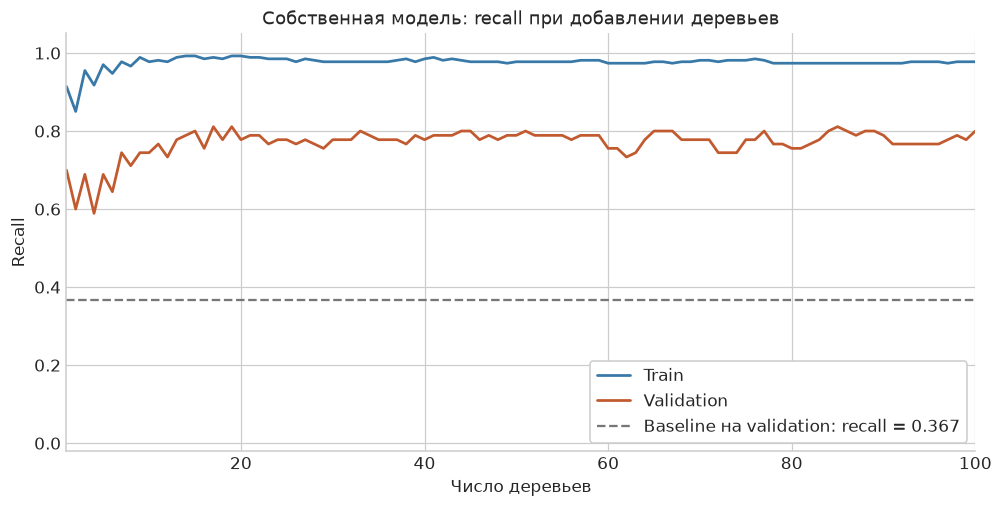

In [11]:
custom_probability_sums = {name: np.zeros(len(target)) for name, target in curve_targets.items()}
custom_curve_rows = []


def record_custom_iteration(tree_count, newest_tree):
    for name, features in curve_features.items():
        custom_probability_sums[name] += newest_tree.predict_proba(features)[:, 1]
        probability = custom_probability_sums[name] / tree_count
        custom_curve_rows.append({
            "Деревьев": tree_count,
            "Выборка": name,
            **classification_metrics(curve_targets[name], probability),
        })


custom_growing_rf = RandomForestClassifierScratch(**custom_fixed_params, **best_custom_params)
custom_growing_rf.fit(X_train, y_train, on_tree=record_custom_iteration)
custom_learning_curve = pd.DataFrame(custom_curve_rows)
custom_learning_curve.to_csv(results_dir / "custom_rf_learning_curve.csv", index=False)

custom_probabilities = {}
custom_predictions = {}
custom_metric_rows = []
for name, (features, target) in splits.items():
    probability = best_custom_rf.predict_proba(features)[:, 1]
    custom_probabilities[name] = probability
    custom_predictions[name] = (probability > 0.5).astype(int)
    custom_metric_rows.append({"Выборка": name, **classification_metrics(target, probability)})

custom_metrics = pd.DataFrame(custom_metric_rows).set_index("Выборка")
custom_metrics.to_csv(results_dir / "custom_rf_metrics.csv")

display(Markdown(
    f"Выбрано: **{best_custom_params['n_estimators']} деревьев**, "
    f"`max_depth={best_custom_params['max_depth']}`, "
    f"`min_samples_leaf={best_custom_params['min_samples_leaf']}`; "
    f"F2 validation — **{best_custom_val_f2:.4f}**."
))

fig, ax = plt.subplots(figsize=(9, 4.5), layout="constrained")
for name, label, color in [("train", "Train", "#3979A8"), ("val", "Validation", "#C25A30")]:
    part = custom_learning_curve.loc[custom_learning_curve["Выборка"].eq(name)]
    ax.plot(part["Деревьев"], part["Recall"], label=label, color=color, linewidth=1.8)
ax.axhline(baseline_metrics.loc["val", "Recall"], color="#777777", linestyle="--",
           label=f'Baseline на validation: recall = {baseline_metrics.loc["val", "Recall"]:.3f}')
ax.set(xlabel="Число деревьев", ylabel="Recall", title="Собственная модель: recall при добавлении деревьев", ylim=(-0.02, 1.05))
ax.set_xlim(1, best_custom_params["n_estimators"])
ax.legend(loc="lower right", frameon=True, facecolor="white", framealpha=1)
plt.show()

## Сводное сравнение

Основная метрика — **F2**, поскольку приоритетом является обнаружение ушедших клиентов.
Recall показывает долю найденных ушедших клиентов, precision — долю верных предупреждений.
F1 отражает равный баланс recall и precision; accuracy приведена как вспомогательная метрика.

In [12]:
metric_columns = ["F2", "Recall", "Precision", "F1", "Accuracy"]
all_models_comparison = pd.concat(
    {"Baseline": baseline_metrics, "Sklearn forest": rf_metrics, "Custom forest": custom_metrics},
    names=["Модель", "Выборка"],
)[metric_columns]
all_models_comparison.to_csv(results_dir / "all_models_comparison.csv")
model_comparison = pd.concat(
    {"Baseline": baseline_metrics, "Random forest": rf_metrics}, names=["Модель", "Выборка"]
)[metric_columns]
model_comparison.to_csv(results_dir / "baseline_vs_sklearn_rf.csv")
all_models_comparison.style.format("{:.4f}")

## Вывод

**Оба леса превосходят baseline по F2 и recall на test.** У baseline F2 = 0,465,
recall = 0,416; у sklearn — 0,741 и 0,708, у собственной модели — 0,753 и 0,719.
Жалоба — сильный сигнал оттока, но правило не обнаруживает ушедших без жалоб.
Леса используют сочетания признаков и находят больше таких клиентов.

**Разница между реализациями невелика.** Разница между sklearn моделью и собственной незначительна. Рассмотрим две важные метрики - recall и  F2. На test они имеют значения в районе 0,7 и 0,75 соответственно - значения отличаются от train достаточно значительно, что могло бы говорить о переобучении, но его модели избежали за счет перебора количества деревьев в лесу(обратим внимание, что после валидации были выбраны модели с числом деревьев 100, которое не являлось максимальным, а значит, этого количества должно быть достаточно). Другой причиной может являться несбалансированность классов. Эту проблему можно было бы решить за счет добавления весов классов.